<a href="https://colab.research.google.com/github/braswellcolin/mane4961/blob/main/hw4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from tensorflow.keras.datasets import cifar10

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training images:", x_train.shape)
print("Test images:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 819s 5us/step
Training images: (50000, 32, 32, 3)
Test images: (10000, 32, 32, 3)


1a

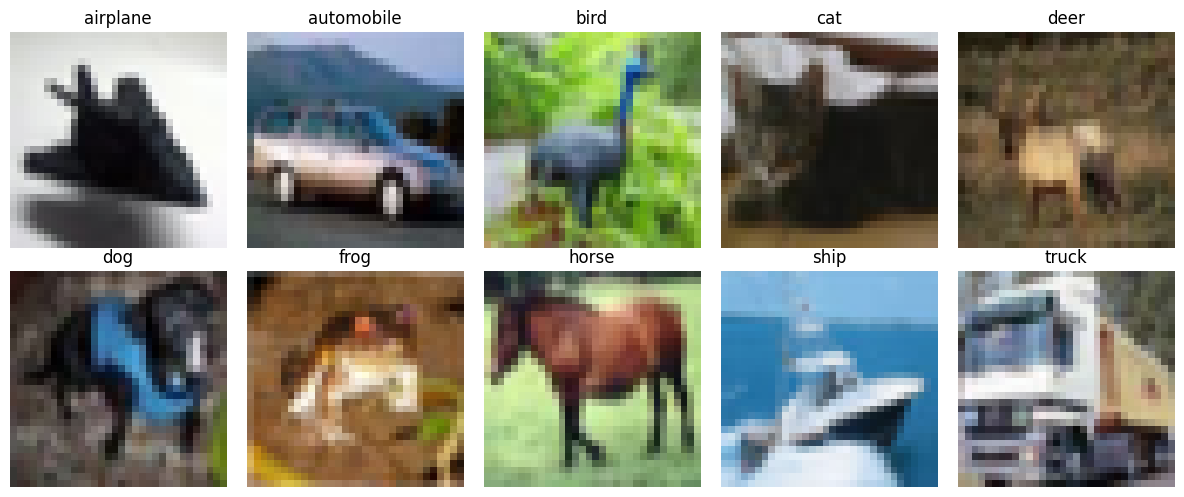

In [3]:
import numpy as np
import matplotlib.pyplot as plt

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(12, 5))

for i in range(10):
    index = np.where(y_train.flatten() == i)[0][0]
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[index])
    plt.title(class_names[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

1b

In [4]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split

# Flatten and normalize the images, then split 70% training / 30% validation
X = x_train.reshape(-1, 3072).astype("float32") / 255.0
y = y_train.flatten()

X_train, X_val, y_fit, y_val = train_test_split(
    X, y, test_size=0.30, random_state=123, stratify=y
)

best_accuracy = -1

# Grid search: try every combination
for neurons in [64, 128]:
    for learning_rate in [0.001, 0.0001]:
        tf.keras.utils.set_random_seed(123)

        model = Sequential([
            Input(shape=(3072,)),
            Dense(neurons, activation="relu"),
            Dense(10, activation="softmax")
        ])

        model.compile(
            optimizer=Adam(learning_rate=learning_rate),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        print(f"Trying neurons={neurons}, learning rate={learning_rate}")

        history = model.fit(
            X_train, y_fit,
            validation_data=(X_val, y_val),
            epochs=10,
            batch_size=128,
            verbose=0
        )

        accuracy = history.history["val_accuracy"][-1]
        print(f"Validation accuracy: {accuracy:.4f}")

        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_parameters = (neurons, learning_rate)
            best_model = model
            best_history = history

# Keep the best network and its training history for parts (c) and (d)
model = best_model
history = best_history

print("\nBest neurons:", best_parameters[0])
print("Best learning rate:", best_parameters[1])
print("Best validation accuracy:", best_accuracy)

Trying neurons=64, learning rate=0.001
Validation accuracy: 0.4003
Trying neurons=64, learning rate=0.0001
Validation accuracy: 0.4285
Trying neurons=128, learning rate=0.001
Validation accuracy: 0.4293
Trying neurons=128, learning rate=0.0001
Validation accuracy: 0.4475

Best neurons: 128
Best learning rate: 0.0001
Best validation accuracy: 0.4474666714668274


1c and 1d

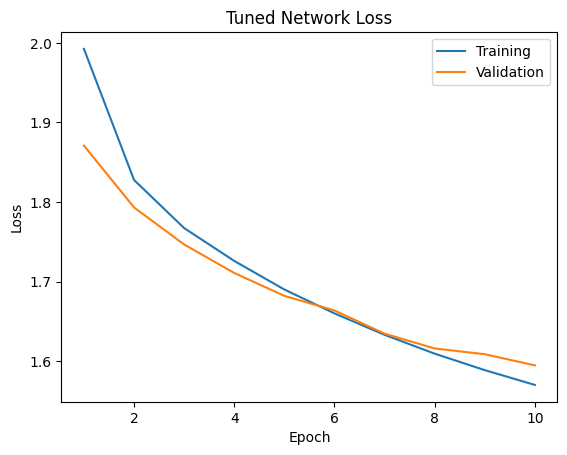

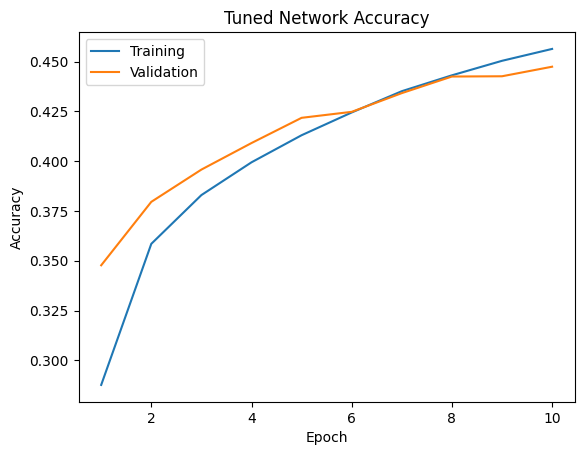

Final training loss: 1.5699865818023682
Final validation loss: 1.594560980796814
Final training accuracy: 0.4564000070095062
Final validation accuracy: 0.4474666714668274


In [5]:
import matplotlib.pyplot as plt

epochs = range(1, len(history.history["loss"]) + 1)

plt.figure()
plt.plot(epochs, history.history["loss"], label="Training")
plt.plot(epochs, history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Tuned Network Loss")
plt.legend()
plt.show()

plt.figure()
plt.plot(epochs, history.history["accuracy"], label="Training")
plt.plot(epochs, history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Tuned Network Accuracy")
plt.legend()
plt.show()

print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])
print("Final training accuracy:", history.history["accuracy"][-1])
print("Final validation accuracy:", history.history["val_accuracy"][-1])

2a

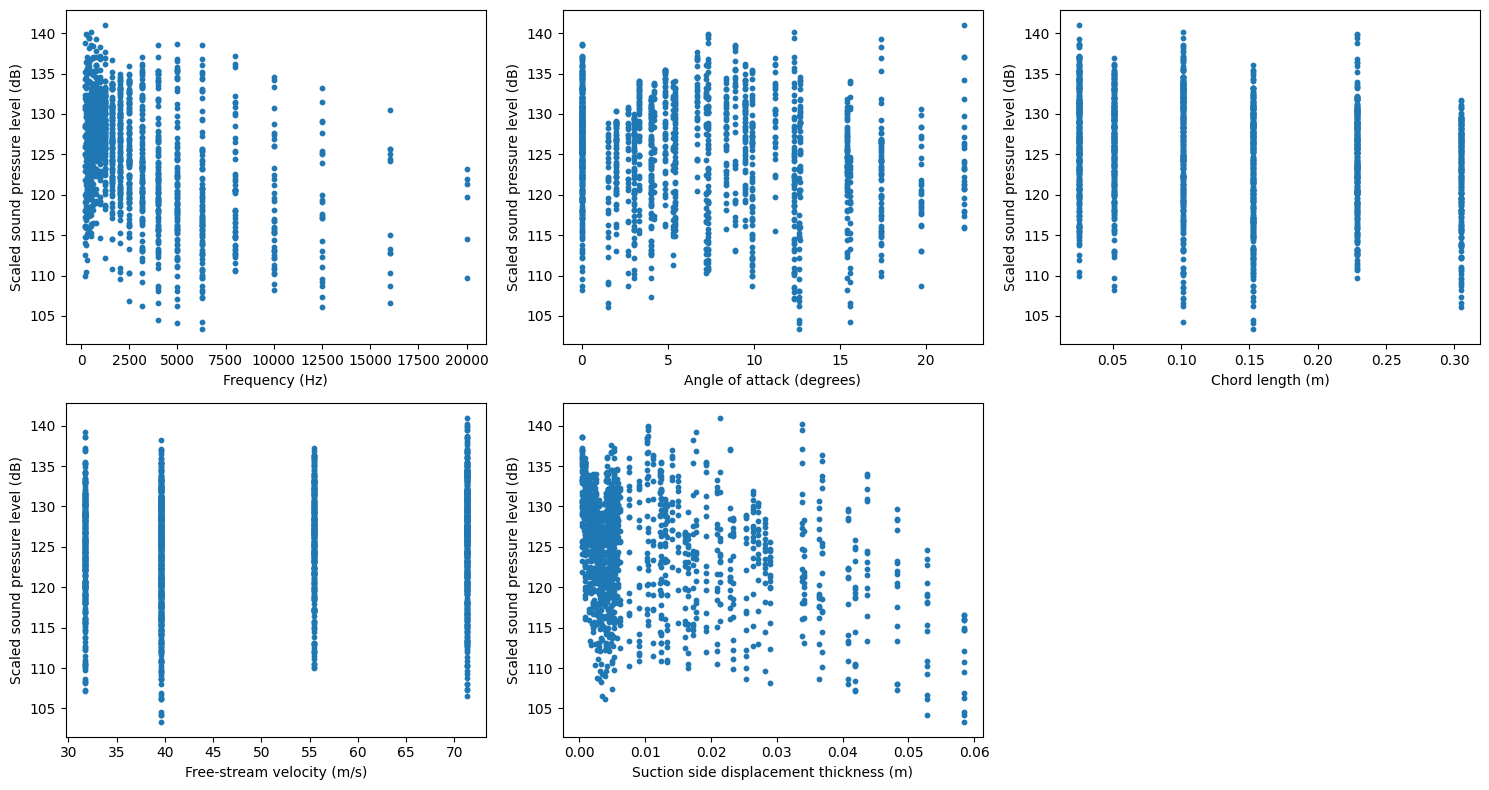

In [1]:
import numpy as np
import matplotlib.pyplot as plt

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00291/airfoil_self_noise.dat"
airfoil = np.loadtxt(url)

X_airfoil = airfoil[:, :5]
y_airfoil = airfoil[:, 5]

labels = [
    "Frequency (Hz)",
    "Angle of attack (degrees)",
    "Chord length (m)",
    "Free-stream velocity (m/s)",
    "Suction side displacement thickness (m)"
]

plt.figure(figsize=(15, 8))

for i in range(5):
    plt.subplot(2, 3, i + 1)
    plt.scatter(X_airfoil[:, i], y_airfoil, s=10)
    plt.xlabel(labels[i])
    plt.ylabel("Scaled sound pressure level (dB)")

plt.tight_layout()
plt.show()

2b  

In [5]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

tf.keras.utils.set_random_seed(123)

X_train2, X_val2, y_train2, y_val2 = train_test_split(
    X_airfoil, y_airfoil, test_size=0.30, random_state=123
)

scaler = StandardScaler()
X_train2 = scaler.fit_transform(X_train2)
X_val2 = scaler.transform(X_val2)

model_airfoil = Sequential([
    Input(shape=(5,)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1)
])

model_airfoil.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)

history_airfoil = model_airfoil.fit(
    X_train2, y_train2,
    validation_data=(X_val2, y_val2),
    epochs=100,
    batch_size=32,
    verbose=1
)

y_pred = model_airfoil.predict(X_val2, verbose=0).flatten()
r2 = r2_score(y_val2, y_pred)

print("Validation R²:", r2)

Epoch 1/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - loss: 15326.3330 - mean_absolute_error: 123.6003 - val_loss: 15117.5264 - val_mean_absolute_error: 122.7258
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 14557.6914 - mean_absolute_error: 120.4061 - val_loss: 13947.1035 - val_mean_absolute_error: 117.7957
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 12922.0469 - mean_absolute_error: 113.2585 - val_loss: 11710.7842 - val_mean_absolute_error: 107.6788
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 10162.0898 - mean_absolute_error: 99.8733 - val_loss: 8364.4893 - val_mean_absolute_error: 90.1932
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 6592.3896 - mean_absolute_error: 78.8233 - val_loss: 4690.5527 - val_mean_absolute_error: 65.1867
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 3337.5886 - mean_absolute_error: 52.8773 - val_loss: 2058.1523 - val_mean_absolute_error: 40.4281
Epoch 7/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 